# 1. Подготовка данных

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss, confusion_matrix)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
plt.rcParams.update({'figure.figsize': (14, 4), 'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option('display.max_columns', None)

data_path = Path('../data') / 'deals_all_opt_2026-09-11__risk_uniform.csv'
validation_start = pd.Timestamp('2023-01-01')
test_start = pd.Timestamp('2025-01-01')
windows = [1, 3, 5, 7, 14]
probability_grid = np.arange(0.30, 0.71, 0.05).round(2)

In [3]:
trades = pd.read_csv(data_path, parse_dates=['entry_date', 'exit_date'])
trades = trades.sort_values(['entry_date', 'exit_date']).reset_index(drop=True)
trades['entry_day'] = trades.entry_date.dt.normalize()
trades['exit_day'] = trades.exit_date.dt.normalize()
cash_initial = float(trades.start_equity.iloc[0])
test_end = trades.exit_day.max()
calendar = pd.date_range(trades.entry_day.min(), test_end, name='Date')

events = trades.groupby('exit_date').profit_abs.sum().sort_index()
equity = cash_initial + events.cumsum()
drawdown = ((equity / equity.cummax().clip(lower=cash_initial) - 1) * 100).clip(upper=0)
underwater = drawdown.lt(-1e-10)
episode_id = (~underwater).cumsum()
episode_start = drawdown.index.to_series().where(underwater & ~underwater.shift(fill_value=False))
episode_start = episode_start.ffill().where(underwater)

last_close = events.index.searchsorted(calendar, side='left') - 1

def at_day_start(series):
    values = series.reindex(events.index).to_numpy()
    return pd.Series(values[np.maximum(last_close, 0)], index=calendar).where(last_close >= 0)

daily = trades.assign(win=trades.profit_abs.gt(0)).groupby('exit_day').agg(
    pnl=('profit_abs', 'sum'), wins=('win', 'sum'), closes=('win', 'size')
).reindex(calendar, fill_value=0)
daily_balance = cash_initial + daily.pnl.cumsum()
opening_balance = daily_balance.shift(1, fill_value=cash_initial)
known_start = at_day_start(episode_start)
features = pd.DataFrame({
    'drawdown_pct': at_day_start(drawdown).fillna(0),
    'days_underwater': (calendar.to_series() - known_start).dt.total_seconds().div(86400).fillna(0),
})
for days in windows:
    closes = daily.closes.rolling(days).sum().shift(1)
    wins = daily.wins.rolling(days).sum().shift(1)
    features[f'closes_{days}d'] = closes
    features[f'winrate_{days}d'] = wins / closes.where(closes.gt(0))
    features[f'return_{days}d'] = (opening_balance / opening_balance.shift(days) - 1) * 100

features = features.iloc[max(windows):]

# 2. Разметка данных

Метка `1` — от начала снижения до первого дна включительно, если дно глубже заданной границы. Остальные известные состояния — `0`. Эпизоды, пересекающие границы выборок, не размечаем для следующего отрезка; незавершённые эпизоды исключаем из обучения и валидации. На тесте у незавершённого эпизода метка `1` допустима только до наблюдаемого дна, если порог уже пробит; неопределённый остаток исключаем из ML-метрик.

### Способ 1: дно глубже −3,5%

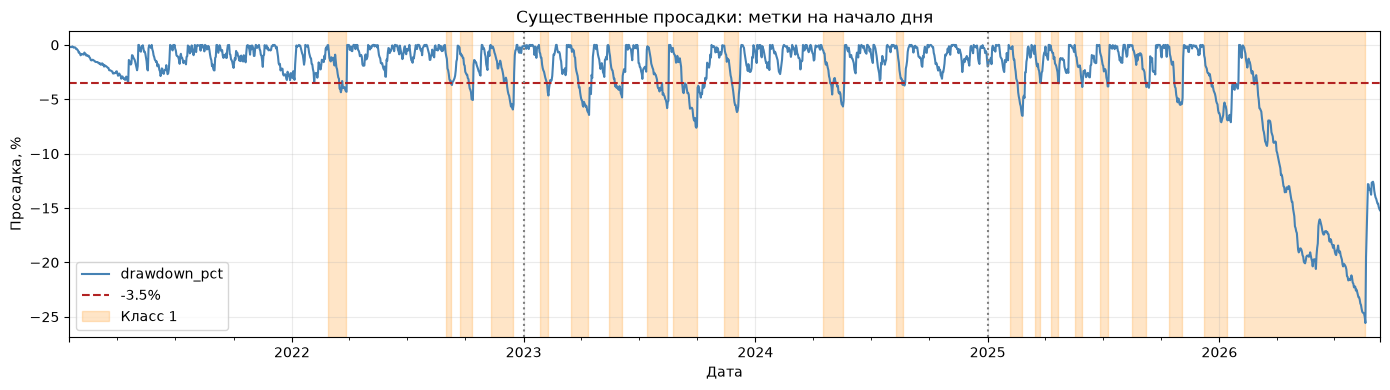

In [4]:
def label_episodes(start, stop, depth_threshold, include_open=False):
    history = drawdown.loc[drawdown.index < stop]
    dd_mask = underwater.reindex(history.index)
    labels = pd.Series(0.0, index=history.index)

    for _, episode in history[dd_mask].groupby(episode_id):
        begin = episode.index[0]
        is_open = episode.index[-1] == history.index[-1]
        trough = episode.idxmin()
        if begin < start or is_open:
            labels.loc[episode.index] = np.nan
        if begin >= start and episode.min() < depth_threshold and (not is_open or include_open):
            labels.loc[episode.loc[:trough].index] = 1

    return at_day_start(labels).loc[(calendar >= start) & (calendar < stop)]

train_start = features.index[0]
test_stop = test_end + pd.Timedelta(days=1)

def prepare_labels(depth_threshold):
    train = label_episodes(train_start, validation_start, depth_threshold)
    validation = label_episodes(validation_start, test_start, depth_threshold)
    test = label_episodes(test_start, test_stop, depth_threshold, include_open=True)
    y_train, y_validation, y_test = (y.dropna().astype(int) for y in (train, validation, test))
    fig, ax = plt.subplots()
    label_view = pd.concat([y_train, y_validation, y_test]).reindex(features.index)
    features.drawdown_pct.plot(ax=ax, color='steelblue')
    ax.axhline(depth_threshold, color='firebrick', linestyle='--', label=f'{depth_threshold:g}%')
    ax.fill_between(label_view.index, 0, 1, where=label_view.eq(1),
                    transform=ax.get_xaxis_transform(), step='post', color='darkorange',
                    alpha=0.22, label='Класс 1')
    for boundary in [validation_start, test_start]:
        ax.axvline(boundary, color='gray', linestyle=':')
    ax.set(title='Существенные просадки: метки на начало дня', ylabel='Просадка, %', xlabel='Дата')
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    return y_train, y_validation, y_test

labels_1 = prepare_labels(-3.5)

### Способ 2: дно глубже −2%

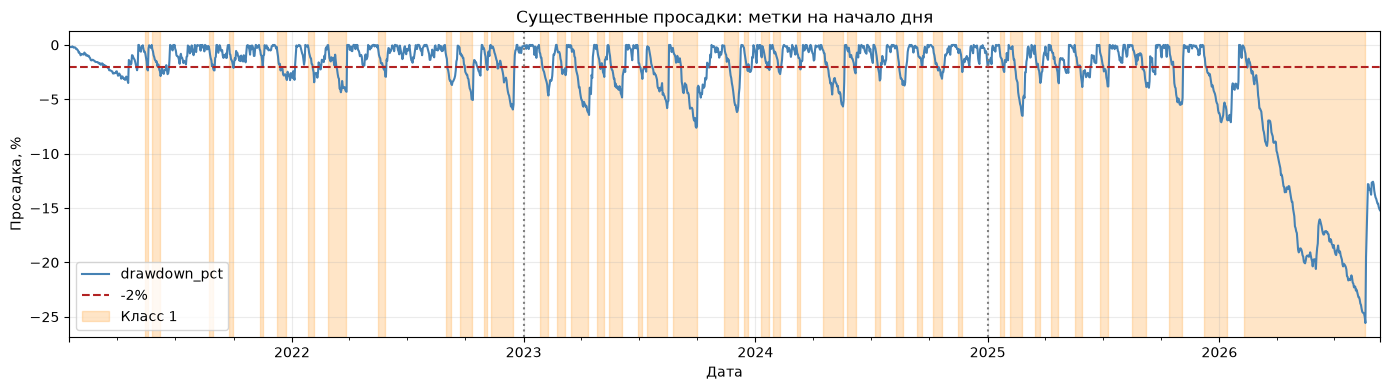

In [5]:
labels_2 = prepare_labels(-2.0)

### Способ 3: дно глубже −5%

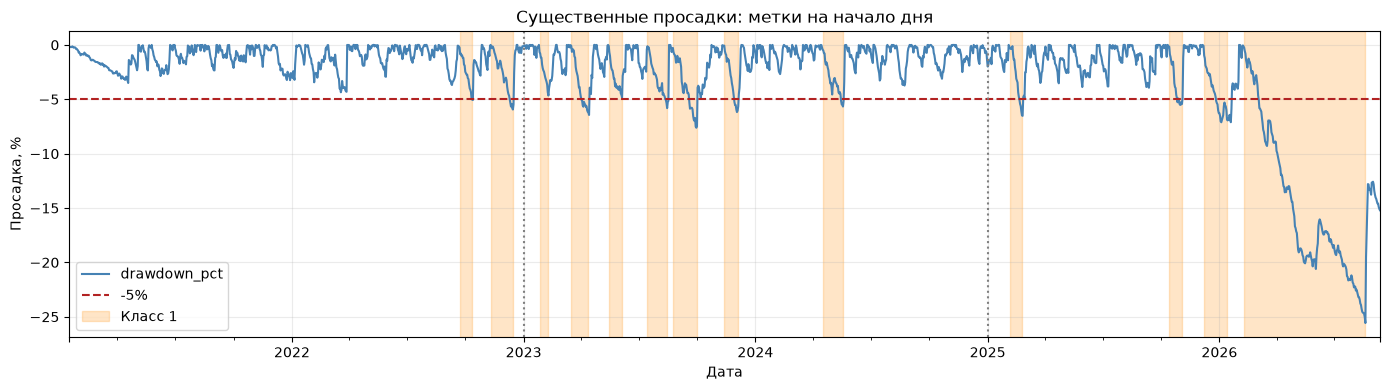

In [6]:
labels_3 = prepare_labels(-5.0)

# 3. Моделирование

Логистическая регрессия с L2 (`C=1`), заполнение пропусков медианой и стандартизация. Обучение: 2021–2022; подбор порога и множителя каждого фильтра по Calmar: 2023–2024; проверка: 2025–2026 YTD. Модель и признаки после валидации не меняем, сглаживание не применяем.

Для ML выбираем лучшую по Calmar настройку из всей сетки: ×0, ×0,5 или ×0,75. При ×0 новые входы временно пропускаются; при сигнале ниже порога они снова открываются полным объёмом. Уже открытые позиции не меняются.

Обычный фильтр и Baseline общие для всех способов. Метки разных способов описывают разные события: сравниваем торговые результаты, а не ранжируем по F1.

In [7]:
drawdown_ci_confidence = 0.95
drawdown_ci_resamples = 2000
drawdown_ci_block_days = 30
drawdown_ci_seed = 42

def drawdown_tail_ci(depth):
    values = depth.to_numpy(dtype=float)
    n = len(values)
    if n < 2 or not np.isfinite(values).all():
        return (np.nan,) * 4
    block_days = min(drawdown_ci_block_days, max(1, n // 4))
    rng = np.random.default_rng(drawdown_ci_seed)
    starts = rng.integers(0, n, size=(drawdown_ci_resamples, int(np.ceil(n / block_days))))
    indices = ((starts[:, :, None] + np.arange(block_days)) % n).reshape(drawdown_ci_resamples, -1)[:, :n]
    samples = values[indices]
    dar = np.quantile(samples, 0.95, axis=1)
    tail = samples >= dar[:, None]
    cdar = np.where(tail, samples, 0.0).sum(axis=1) / tail.sum(axis=1)
    alpha = (1 - drawdown_ci_confidence) / 2
    low, high = np.quantile(np.column_stack([dar, cdar]), [alpha, 1 - alpha], axis=0)
    return low[0], high[0], low[1], high[1]

def portfolio_result(block_entries, start, end, reduced_multiplier=0.0, full_metrics=False):
    restricted = trades.entry_day.map(block_entries).eq(True)
    size = pd.Series(np.where(restricted, reduced_multiplier, 1.0), index=trades.index)
    pnl = (trades.profit_abs * size).groupby(trades.exit_date).sum().sort_index()
    opening = cash_initial + pnl.loc[pnl.index < start].sum()
    path = opening + pnl.loc[(pnl.index >= start) & (pnl.index < end)].cumsum()
    path = pd.concat([pd.Series([opening], index=[start - pd.Timedelta(nanoseconds=1)]), path])
    returns = (path / opening - 1) * 100
    dd = (path / path.cummax() - 1) * 100
    mdd = -dd.min()
    cagr = ((path.iloc[-1] / opening) ** (365.25 / (end - start).days) - 1) * 100
    entries = trades.entry_day.ge(start) & trades.entry_day.lt(end)
    metrics = {'Net_PnL_USDT': path.iloc[-1] - opening, 'Return_pct': returns.iloc[-1],
               'MDD_pct': mdd, 'Calmar': cagr / mdd if mdd > 0 else np.nan,
               'Trades_skipped_pct': size.loc[entries].eq(0).mean() * 100}
    if full_metrics:
        dates = pd.date_range(start, end - pd.Timedelta(days=1))
        daily_pnl = pnl.loc[(pnl.index >= start) & (pnl.index < end)]
        daily_pnl = daily_pnl.groupby(daily_pnl.index.normalize()).sum().reindex(dates, fill_value=0)
        balance = opening + daily_pnl.cumsum()
        daily_return = daily_pnl / balance.shift(1, fill_value=opening)
        daily_peak = balance.cummax().clip(lower=opening)
        depth = (1 - balance / daily_peak) * 100
        underwater = (daily_peak - balance).gt(1e-9)
        episodes = (~underwater).cumsum()
        serious_dd_threshold_pct = 3.0
        max_cash_dd = (path.cummax() - path).max()
        dar = depth.quantile(0.95)
        dar_low, dar_high, cdar_low, cdar_high = drawdown_tail_ci(depth)
        vol = daily_return.std()
        downside = np.sqrt(daily_return.clip(upper=0).pow(2).mean())
        metrics.update({
            'CAGR_pct': cagr,
            'DaR95_pct': dar,
            'CDaR95_pct': depth.loc[depth.ge(dar)].mean(),
            'RecoveryFactor': metrics['Net_PnL_USDT'] / max_cash_dd if max_cash_dd > 0 else np.nan,
            'Sharpe': daily_return.mean() / vol * np.sqrt(365) if vol > 0 else np.nan,
            'Sortino': daily_return.mean() / downside * np.sqrt(365) if downside > 0 else np.nan,
            'Max_DD_duration_days': int(underwater.groupby(episodes).sum().max()),
            'Time_underwater_pct': underwater.mean() * 100,
            'Serious_DD_count': int(depth.groupby(episodes).max().gt(serious_dd_threshold_pct + 1e-10).sum()),
            'Serious_DD_days': int(depth.gt(serious_dd_threshold_pct + 1e-10).sum()),
            'Avg_multiplier': size.loc[entries].mean(),
            'Trades_half_pct': size.loc[entries].eq(0.5).mean() * 100,
            'Switches': int(block_entries.ne(block_entries.shift(1, fill_value=False)).sum()),
            'DaR95_pct_CI_low': dar_low,
            'DaR95_pct_CI_high': dar_high,
            'CDaR95_pct_CI_low': cdar_low,
            'CDaR95_pct_CI_high': cdar_high,
        })
    return metrics, returns, dd

reduced_grid = [0.0, 0.5, 0.75]
drawdown_grid = np.arange(-5.5, -1.49, 0.5)
validation_days = features.index[(features.index >= validation_start) &
                                    (features.index < test_start)]
validation_drawdown = features.drawdown_pct.loc[validation_days]

def tune_filter(signal, thresholds, condition):
    scores = pd.DataFrame([
        {'Threshold': threshold, 'Reduced_multiplier': reduced,
         **portfolio_result(condition(signal, threshold), validation_start, test_start, reduced)[0]}
        for threshold in thresholds for reduced in reduced_grid
    ])
    scores = scores.sort_values(['Calmar', 'Net_PnL_USDT'], ascending=False)
    return scores

dd_scores = tune_filter(validation_drawdown, drawdown_grid, pd.Series.lt)
dd_selected = dd_scores.iloc[0]
dd_scores['Selected'] = dd_scores.index == dd_selected.name
drawdown_threshold, dd_multiplier = dd_selected[['Threshold', 'Reduced_multiplier']]
validation_baseline = portfolio_result(
    pd.Series(False, index=validation_days), validation_start, test_start
)[0]

test_days = features.loc[test_start:test_end].index
test_benchmarks = {
    'Baseline': (pd.Series(False, index=test_days), 1.0),
    'Фильтр по текущей просадке': (
        features.drawdown_pct.loc[test_days].lt(drawdown_threshold), dd_multiplier
    ),
}
benchmark_runs = {
    name: portfolio_result(flags, test_start, test_stop, reduced, full_metrics=True)
    for name, (flags, reduced) in test_benchmarks.items()
}

def classification_metrics(y, probability, decision_threshold):
    score = probability.loc[y.index]
    prediction = score.ge(decision_threshold)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        'Дней': len(y), 'Дней класса 1': int(y.sum()),
        'Эпизодов класса 1': known_start.loc[y.index[y.eq(1)]].nunique(),
        'Accuracy': accuracy_score(y, prediction),
        'Balanced accuracy': balanced_accuracy_score(y, prediction),
        'Precision': precision_score(y, prediction, zero_division=0),
        'Recall': recall_score(y, prediction, zero_division=0),
        'F1': f1_score(y, prediction, zero_division=0),
        'ROC AUC': roc_auc_score(y, score) if y.nunique() == 2 else np.nan,
        'Average precision': average_precision_score(y, score) if y.nunique() == 2 else np.nan,
        'Brier': brier_score_loss(y, score),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }

def run_study(labels, depth_threshold, feature_columns=None, classifier=None,
              method_name='Логистическая регрессия'):
    x = features if feature_columns is None else features.loc[:, feature_columns]
    title = 'все признаки' if feature_columns is None else 'только глубина'
    y_train, y_validation, y_test = labels
    if y_train.nunique() < 2:
        raise ValueError(f'Для порога {depth_threshold:g}% в обучении отсутствует один из классов.')
    model_steps = (StandardScaler(), LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000))
    if classifier is not None:
        model_steps = (classifier,)
    model = make_pipeline(SimpleImputer(strategy='median'), *model_steps)
    model.fit(x.loc[y_train.index], y_train)
    probability = pd.Series(model.predict_proba(x)[:, 1], index=x.index, name='Probability')
    ml_scores = tune_filter(probability.loc[validation_days], probability_grid, pd.Series.ge)
    ml_selected = ml_scores.iloc[0]
    ml_scores['Selected'] = ml_scores.index == ml_selected.name
    decision_threshold, ml_multiplier = ml_selected[['Threshold', 'Reduced_multiplier']]
    print(f'ML: порог сигнала {decision_threshold:.2f}, объём ×{ml_multiplier:g}; '
          f'обычный фильтр: порог {drawdown_threshold:g}%, объём ×{dd_multiplier:g}.')

    validation_grid = pd.concat({
        'Baseline': pd.DataFrame([{'Reduced_multiplier': 1.0, 'Selected': False, **validation_baseline}]),
        method_name: ml_scores,
        'Фильтр по текущей просадке': dd_scores,
    }, names=['Method', 'Config_ID'])
    base_pnl = validation_baseline['Net_PnL_USDT']
    validation_grid['PnL_delta_USDT'] = validation_grid.Net_PnL_USDT - base_pnl
    validation_grid['PnL_retained_pct'] = validation_grid.Net_PnL_USDT / base_pnl * 100 if base_pnl > 0 else np.nan
    validation_columns = ['Threshold', 'Reduced_multiplier', 'Selected', 'Net_PnL_USDT',
                          'PnL_delta_USDT', 'PnL_retained_pct', 'Return_pct', 'MDD_pct',
                          'Calmar', 'Trades_skipped_pct']
    with pd.option_context('display.max_rows', None):
        display(validation_grid[validation_columns].round(3))

    ml_summary = pd.DataFrame({'Валидация': classification_metrics(y_validation, probability, decision_threshold),
                               'Тест': classification_metrics(y_test, probability, decision_threshold)}).T
    display(ml_summary.round(3))

    ml_run = portfolio_result(probability.loc[test_days].ge(decision_threshold),
                              test_start, test_stop, ml_multiplier, full_metrics=True)
    test_runs = {**benchmark_runs, method_name: ml_run}
    summary = pd.DataFrame({name: run[0] for name, run in test_runs.items()}).T.rename_axis('Method')
    baseline_pnl = summary.loc['Baseline', 'Net_PnL_USDT']
    summary['PnL_delta_USDT'] = summary.Net_PnL_USDT - baseline_pnl
    summary['PnL_retained_pct'] = summary.Net_PnL_USDT / baseline_pnl * 100 if baseline_pnl > 0 else np.nan
    summary_columns = ['Net_PnL_USDT', 'PnL_retained_pct', 'PnL_delta_USDT', 'Return_pct', 'CAGR_pct',
                       'MDD_pct', 'DaR95_pct', 'CDaR95_pct', 'Calmar', 'RecoveryFactor', 'Sharpe', 'Sortino',
                       'Max_DD_duration_days', 'Time_underwater_pct', 'Serious_DD_count', 'Serious_DD_days',
                       'Avg_multiplier', 'Trades_half_pct', 'Trades_skipped_pct', 'Switches',
                       'DaR95_pct_CI_low', 'DaR95_pct_CI_high', 'CDaR95_pct_CI_low', 'CDaR95_pct_CI_high']
    summary = summary[summary_columns]
    display(summary.round(3))

    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    for name, (_, returns, dd) in test_runs.items():
        axes[0].step(returns.index, returns, where='post', label=name)
        axes[1].step(dd.index, dd, where='post', label=name)
    axes[0].set(title=f'{method_name}: тест, разметка {depth_threshold:g}%, {title}', ylabel='Доходность, %')
    axes[1].set(ylabel='Просадка, %', xlabel='Дата закрытия')
    axes[0].legend()
    plt.tight_layout()
    plt.show()
    return {'labels': labels, 'model': model, 'probability': probability, 'method_name': method_name,
            'validation_grid': validation_grid, 'classification': ml_summary, 'summary': summary,
            'threshold': decision_threshold, 'multiplier': ml_multiplier,
            'validation_calmar': ml_selected.Calmar}


### Моделирование: способ 1 (−3,5%)

ML: порог сигнала 0.60, объём ×0; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
Логистическая регрессия    18              0.60                0.00      True   
                           21              0.65                0.00     False   
                           10              0.45                0.50     False   
                           19              0.60                0.50     False   
                           22              0.65                0.50     False   
                           16              0.55                0.50     False   
                           7               0.40                0.50     False   
                           4               0.35                0.50     False   
                           1               0.30                0.50     False   
                           24              0.70                0.00     False   
                           15              0.55                0.00     False   
                           13              0.50                0.50     False   
                           25              0.70                0.50     False   
                           11              0.45                0.75     False   
                           20              0.60                0.75     False   
                           23              0.65                0.75     False   
                           17              0.55                0.75     False   
                           8               0.40                0.75     False   
                           5               0.35                0.75     False   
                           2               0.30                0.75     False   
                           26              0.70                0.75     False   
                           14              0.50                0.75     False   
                           3               0.35                0.00     False   
                           0               0.30                0.00     False   
                           9               0.45                0.00     False   
                           6               0.40                0.00     False   
                           12              0.50                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.806,0.679,0.832,0.389,0.530,0.845,0.735,0.135,504.0,16.0,124.0,79.0
Тест,588.0,341.0,9.0,0.804,0.824,0.945,0.704,0.807,0.911,0.940,0.142,233.0,14.0,101.0,240.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.000,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.000,19.0,10.336,15.272,12.704,15.913
Логистическая регрессия,206146.053,76.655,-62781.919,98.224,49.741,6.270,5.132,5.307,7.933,8.109,2.210,8.445,215.0,89.984,8.0,307.0,0.544,0.000,45.594,23.0,5.032,5.218,5.065,5.438


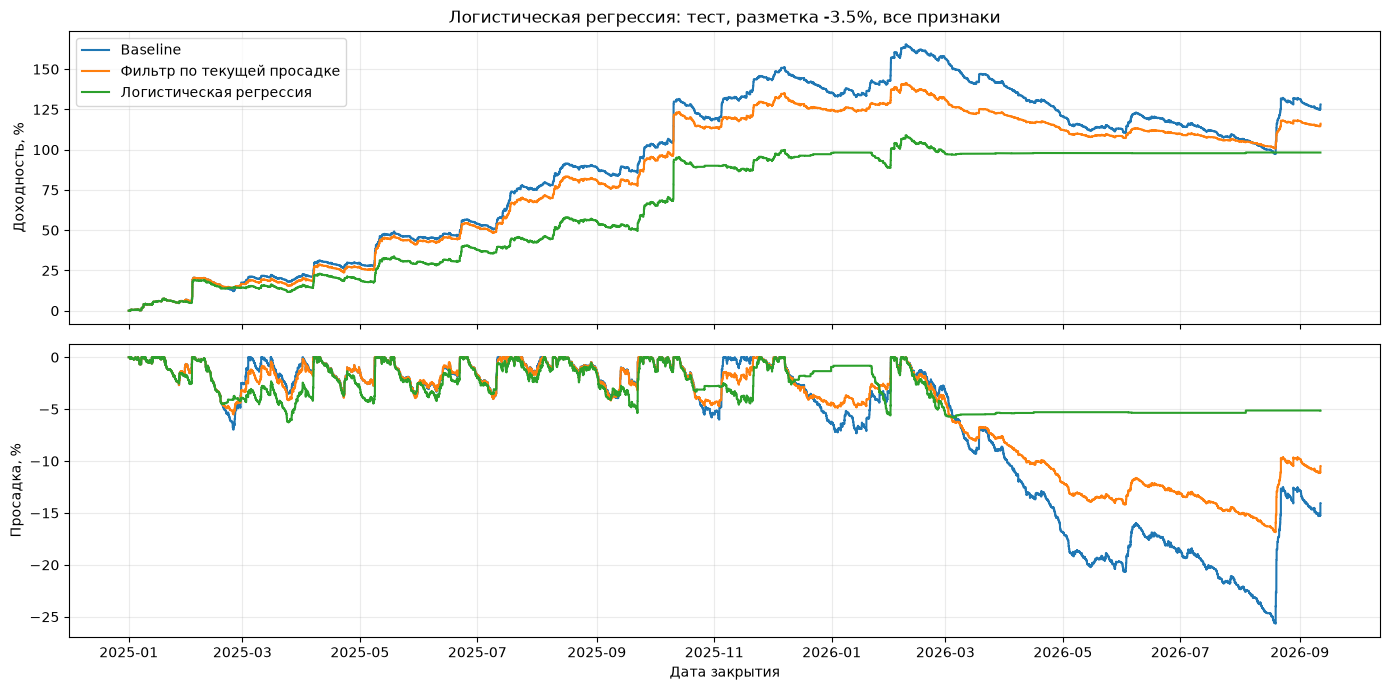

In [8]:
study_1 = run_study(labels_1, -3.5)

### Моделирование: способ 2 (−2%)

ML: порог сигнала 0.40, объём ×0.5; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
Логистическая регрессия    7               0.40                0.50      True   
                           4               0.35                0.50     False   
                           22              0.65                0.50     False   
                           10              0.45                0.50     False   
                           13              0.50                0.50     False   
                           1               0.30                0.50     False   
                           8               0.40                0.75     False   
                           25              0.70                0.50     False   
                           5               0.35                0.75     False   
                           23              0.65                0.75     False   
                           11              0.45                0.75     False   
                           14              0.50                0.75     False   
                           19              0.60                0.50     False   
                           16              0.55                0.50     False   
                           26              0.70                0.75     False   
                           2               0.30                0.75     False   
                           20              0.60                0.75     False   
                           9               0.45                0.00     False   
                           21              0.65                0.00     False   
                           17              0.55                0.75     False   
                           12              0.50                0.00     False   
                           6               0.40                0.00     False   
                           18              0.60                0.00     False   
                           24              0.70                0.00     False   
                           15              0.55                0.00     False   
                           3               0.35                0.00     False   
                           0               0.30                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,331.0,20.0,0.822,0.818,0.826,0.773,0.799,0.896,0.869,0.138,338.0,54.0,75.0,256.0
Тест,588.0,349.0,10.0,0.862,0.850,0.860,0.917,0.888,0.941,0.961,0.096,187.0,52.0,29.0,320.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.0,19.0,10.336,15.272,12.704,15.913
Логистическая регрессия,240379.019,89.384,-28548.954,114.535,56.894,14.563,11.603,12.772,3.907,3.291,2.545,10.885,215.0,86.107,3.0,232.0,0.699,60.117,0.0,54.0,9.300,12.964,10.622,13.612


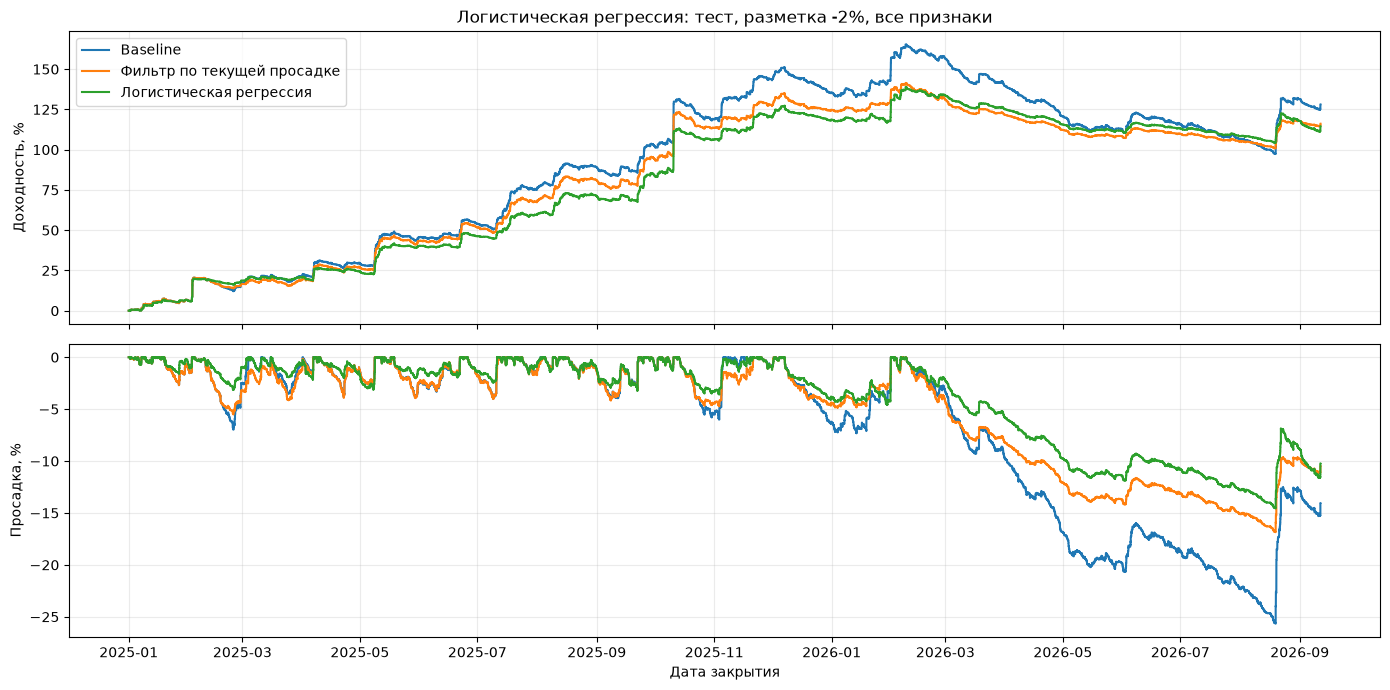

In [9]:
study_2 = run_study(labels_2, -2.0)

### Моделирование: способ 3 (−5%)

ML: порог сигнала 0.30, объём ×0.5; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
Логистическая регрессия    1               0.30                0.50      True   
                           4               0.35                0.50     False   
                           0               0.30                0.00     False   
                           25              0.70                0.50     False   
                           22              0.65                0.50     False   
                           2               0.30                0.75     False   
                           19              0.60                0.50     False   
                           5               0.35                0.75     False   
                           23              0.65                0.75     False   
                           7               0.40                0.50     False   
                           20              0.60                0.75     False   
                           24              0.70                0.00     False   
                           26              0.70                0.75     False   
                           8               0.40                0.75     False   
                           10              0.45                0.50     False   
                           11              0.45                0.75     False   
                           17              0.55                0.75     False   
                           14              0.50                0.75     False   
                           13              0.50                0.50     False   
                           3               0.35                0.00     False   
                           16              0.55                0.50     False   
                           21              0.65                0.00     False   
                           18              0.60                0.00     False   
                           6               0.40                0.00     False   
                           9               0.45                0.00     False   
                           12              0.50                0.00     False   
                           15              0.55                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,192.0,7.0,0.823,0.695,0.827,0.422,0.559,0.831,0.707,0.155,514.0,17.0,111.0,81.0
Тест,588.0,270.0,4.0,0.884,0.881,0.907,0.833,0.869,0.948,0.952,0.094,295.0,23.0,45.0,225.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.0,19.0,10.336,15.272,12.704,15.913
Логистическая регрессия,244712.319,90.995,-24215.654,116.600,57.783,17.195,14.248,15.422,3.360,2.821,2.485,9.526,215.0,87.561,9.0,272.0,0.779,44.142,0.0,37.0,10.338,15.613,12.984,16.257


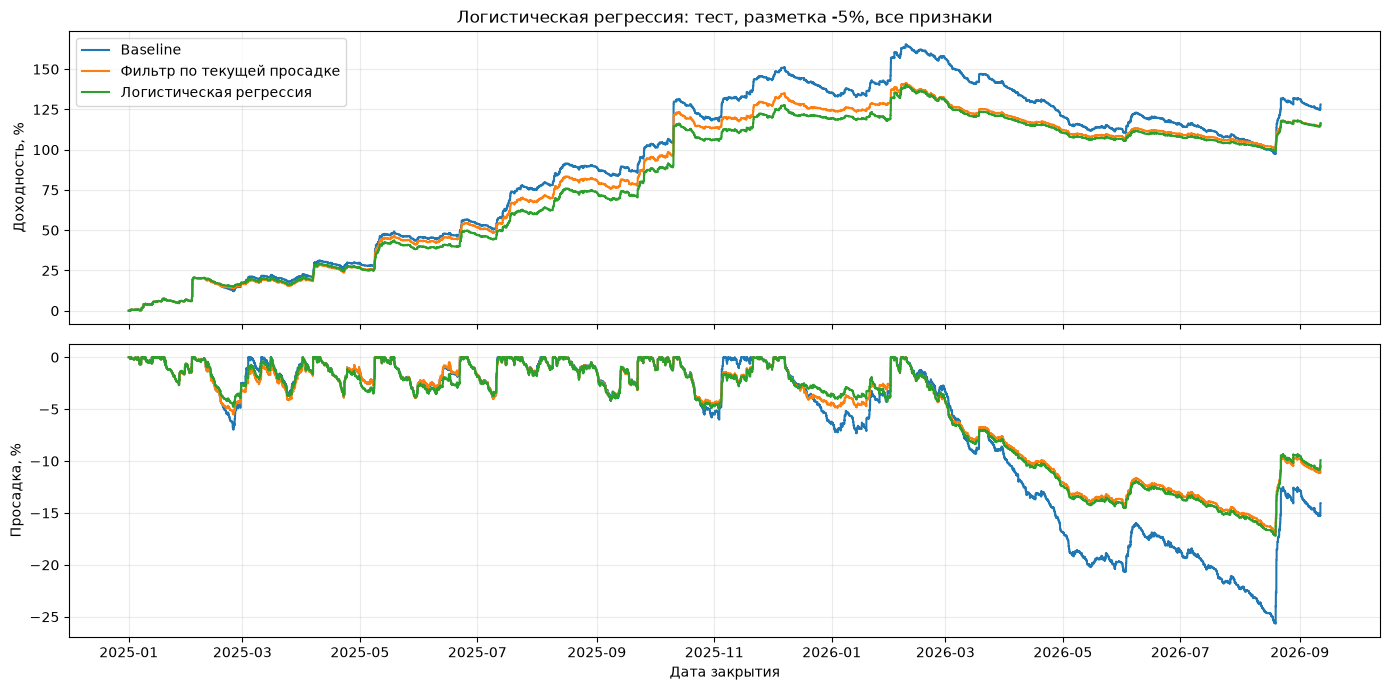

In [10]:
study_3 = run_study(labels_3, -5.0)

### Моделирование: способ 1 (−3,5%), только глубина просадки

Контрольный логрег с одним признаком: глубина просадки портфеля на начало дня. Разметка, даты и сетка управления те же, что у модели с 17 признаками. При одном признаке порог оценки логрега задаёт эквивалентный порог глубины, если коэффициент ненулевой.

ML: порог сигнала 0.55, объём ×0.5; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
Логистическая регрессия    16              0.55                0.50      True   
                           13              0.50                0.50     False   
                           22              0.65                0.50     False   
                           10              0.45                0.50     False   
                           7               0.40                0.50     False   
                           19              0.60                0.50     False   
                           4               0.35                0.50     False   
                           25              0.70                0.50     False   
                           15              0.55                0.00     False   
                           17              0.55                0.75     False   
                           14              0.50                0.75     False   
                           23              0.65                0.75     False   
                           11              0.45                0.75     False   
                           20              0.60                0.75     False   
                           8               0.40                0.75     False   
                           5               0.35                0.75     False   
                           1               0.30                0.50     False   
                           26              0.70                0.75     False   
                           2               0.30                0.75     False   
                           18              0.60                0.00     False   
                           21              0.65                0.00     False   
                           24              0.70                0.00     False   
                           6               0.40                0.00     False   
                           3               0.35                0.00     False   
                           9               0.45                0.00     False   
                           12              0.50                0.00     False   
                           0               0.30                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.820,0.719,0.792,0.488,0.604,0.837,0.710,0.137,494.0,26.0,104.0,99.0
Тест,588.0,341.0,9.0,0.748,0.767,0.888,0.648,0.749,0.877,0.918,0.173,219.0,28.0,120.0,221.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.0,19.0,10.336,15.272,12.704,15.913
Логистическая регрессия,242355.592,90.119,-26572.381,115.477,57.300,16.897,13.953,15.126,3.391,2.838,2.507,9.512,215.0,87.561,8.0,282.0,0.780,44.032,0.0,19.0,10.367,15.317,12.741,15.959


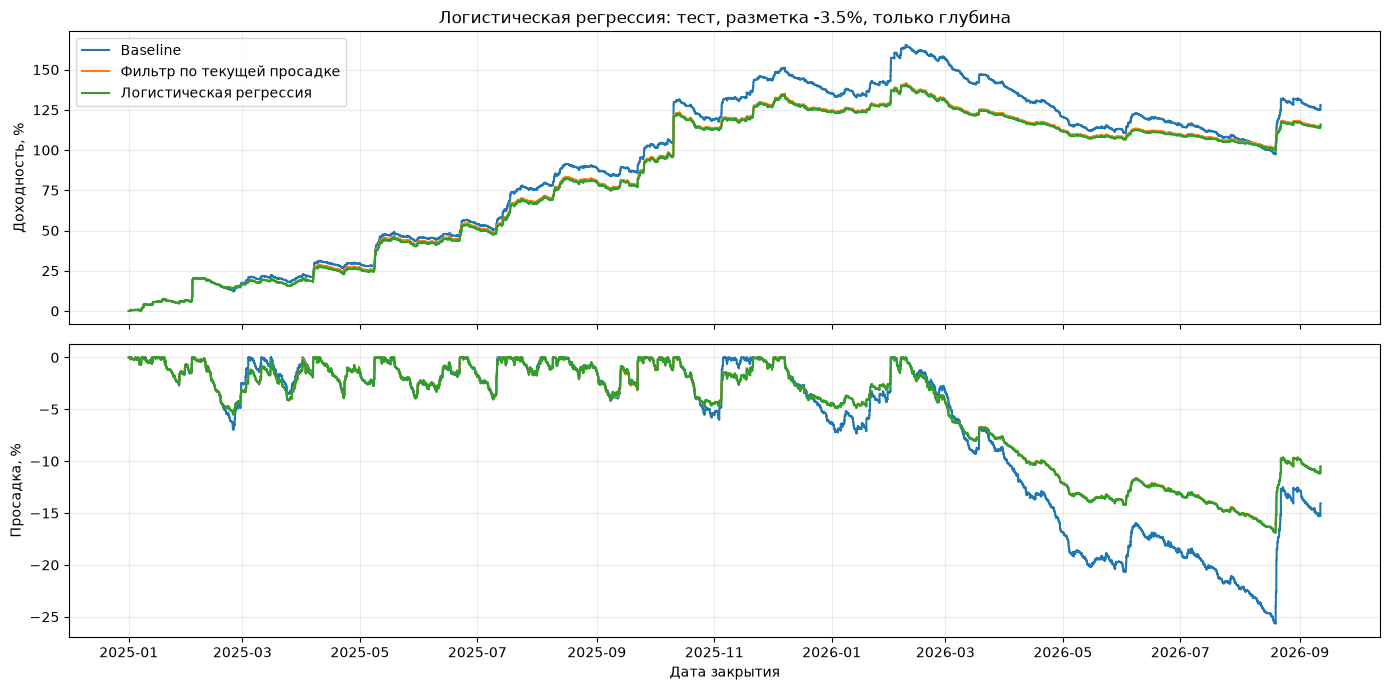

Эквивалентное условие: текущая просадка ≤ -3.48%.


In [11]:
study_depth_only = run_study(labels_1, -3.5, feature_columns=['drawdown_pct'])

depth_model = study_depth_only['model']
depth_score_threshold = study_depth_only['threshold']
depth_coefficient = depth_model[-1].coef_[0, 0] / depth_model[1].scale_[0]
if abs(depth_coefficient) > 1e-12:
    depth_logit = np.log(depth_score_threshold / (1 - depth_score_threshold))
    depth_drawdown_threshold = (
        depth_model[1].mean_[0] + (depth_logit - depth_model[-1].intercept_[0]) / depth_coefficient
    )
    depth_operator = '≤' if depth_coefficient < 0 else '≥'
    print(f'Эквивалентное условие: текущая просадка {depth_operator} {depth_drawdown_threshold:.2f}%.')

### Моделирование: градиентный бустинг (−3,5%)

Модель обучаем на 2021–2022 со стандартными настройками. На 2023–2024 подбираем только порог сигнала и объём новых позиций; итоговая проверка — на 2025–2026.

ML: порог сигнала 0.35, объём ×0.5; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
Градиентный бустинг        4               0.35                0.50      True   
                           1               0.30                0.50     False   
                           13              0.50                0.50     False   
                           10              0.45                0.50     False   
                           7               0.40                0.50     False   
                           22              0.65                0.50     False   
                           19              0.60                0.50     False   
                           25              0.70                0.50     False   
                           16              0.55                0.50     False   
                           11              0.45                0.75     False   
                           8               0.40                0.75     False   
                           5               0.35                0.75     False   
                           2               0.30                0.75     False   
                           14              0.50                0.75     False   
                           3               0.35                0.00     False   
                           0               0.30                0.00     False   
                           23              0.65                0.75     False   
                           12              0.50                0.00     False   
                           20              0.60                0.75     False   
                           24              0.70                0.00     False   
                           26              0.70                0.75     False   
                           9               0.45                0.00     False   
                           17              0.55                0.75     False   
                           6               0.40                0.00     False   
                           21              0.65                0.00     False   
                           18              0.60                0.00     False   
                           15              0.55                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.824,0.740,0.760,0.547,0.636,0.833,0.756,0.137,485.0,35.0,92.0,111.0
Тест,588.0,341.0,9.0,0.675,0.705,0.871,0.516,0.648,0.846,0.879,0.268,221.0,26.0,165.0,176.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.0,19.0,10.336,15.272,12.704,15.913
Градиентный бустинг,211213.951,78.539,-57714.022,100.639,50.815,20.922,17.250,18.820,2.429,2.018,2.173,7.828,215.0,87.884,8.0,280.0,0.827,34.633,0.0,80.0,13.324,19.322,14.523,19.983


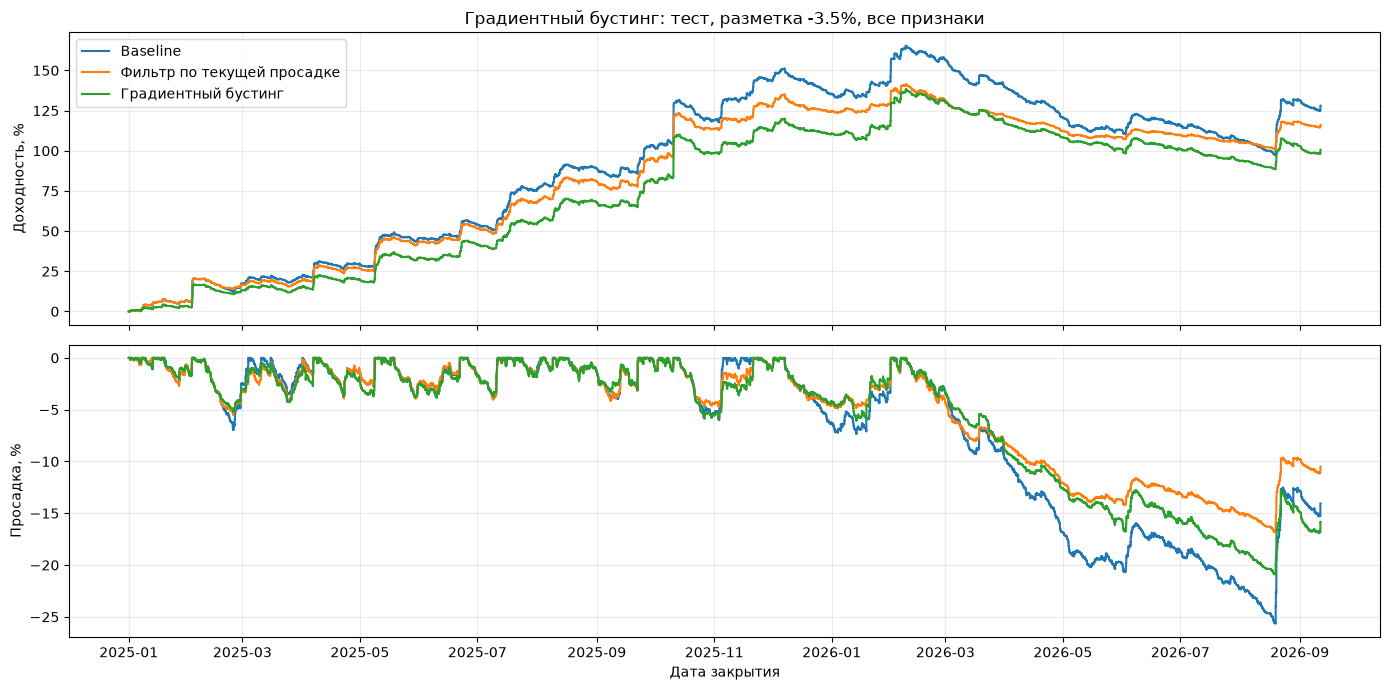

In [12]:
study_boosting = run_study(
    labels_1, -3.5, classifier=GradientBoostingClassifier(random_state=42),
    method_name='Градиентный бустинг'
)

### Моделирование: CatBoost (−3,5%)

Для CatBoost, HistGradientBoosting и AdaBoost оставляем базовые настройки моделей. Каждая модель обучается на 2021–2022 на тех же признаках; на 2023–2024 по Calmar подбираем только порог сигнала и множитель размера новых позиций. Итоговая проверка — на 2025–2026.

ML: порог сигнала 0.70, объём ×0; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
CatBoost                   24              0.70                0.00      True   
                           19              0.60                0.50     False   
                           21              0.65                0.00     False   
                           13              0.50                0.50     False   
                           16              0.55                0.50     False   
                           18              0.60                0.00     False   
                           4               0.35                0.50     False   
                           1               0.30                0.50     False   
                           7               0.40                0.50     False   
                           10              0.45                0.50     False   
                           25              0.70                0.50     False   
                           22              0.65                0.50     False   
                           12              0.50                0.00     False   
                           15              0.55                0.00     False   
                           3               0.35                0.00     False   
                           0               0.30                0.00     False   
                           20              0.60                0.75     False   
                           6               0.40                0.00     False   
                           14              0.50                0.75     False   
                           17              0.55                0.75     False   
                           5               0.35                0.75     False   
                           2               0.30                0.75     False   
                           8               0.40                0.75     False   
                           11              0.45                0.75     False   
                           26              0.70                0.75     False   
                           23              0.65                0.75     False   
                           9               0.45                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.815,0.676,0.948,0.360,0.521,0.841,0.764,0.135,516.0,4.0,130.0,73.0
Тест,588.0,341.0,9.0,0.648,0.691,0.941,0.419,0.580,0.876,0.900,0.238,238.0,9.0,198.0,143.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.000,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.000,19.0,10.336,15.272,12.704,15.913
CatBoost,164001.294,60.983,-104926.679,78.143,40.595,21.773,17.338,18.969,1.864,1.606,1.793,5.975,215.0,89.822,8.0,315.0,0.735,0.000,26.512,61.0,10.406,20.104,13.512,21.035


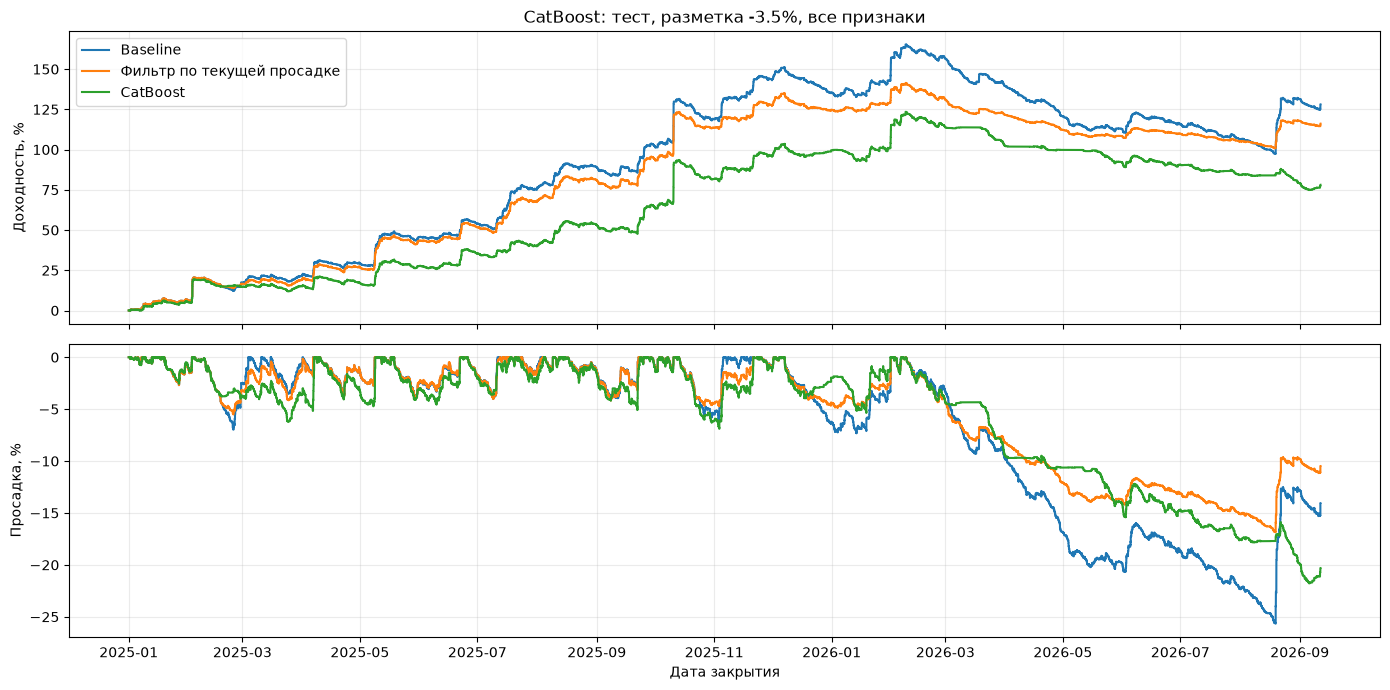

In [13]:
from catboost import CatBoostClassifier

study_catboost = run_study(
    labels_1, -3.5, classifier=CatBoostClassifier(random_seed=42, verbose=False, allow_writing_files=False),
    method_name='CatBoost'
)

### Моделирование: HistGradientBoosting (−3,5%)

ML: порог сигнала 0.50, объём ×0; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
HistGradientBoosting       12              0.50                0.00      True   
                           21              0.65                0.00     False   
                           22              0.65                0.50     False   
                           18              0.60                0.00     False   
                           9               0.45                0.00     False   
                           19              0.60                0.50     False   
                           13              0.50                0.50     False   
                           1               0.30                0.50     False   
                           15              0.55                0.00     False   
                           16              0.55                0.50     False   
                           24              0.70                0.00     False   
                           10              0.45                0.50     False   
                           25              0.70                0.50     False   
                           3               0.35                0.00     False   
                           4               0.35                0.50     False   
                           7               0.40                0.50     False   
                           0               0.30                0.00     False   
                           6               0.40                0.00     False   
                           23              0.65                0.75     False   
                           20              0.60                0.75     False   
                           2               0.30                0.75     False   
                           14              0.50                0.75     False   
                           17              0.55                0.75     False   
                           26              0.70                0.75     False   
                           11              0.45                0.75     False   
                           5               0.35                0.75     False   
                           8               0.40                0.75     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.813,0.696,0.821,0.429,0.563,0.797,0.709,0.163,501.0,19.0,116.0,87.0
Тест,588.0,341.0,9.0,0.656,0.693,0.888,0.466,0.612,0.824,0.863,0.308,227.0,20.0,182.0,159.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.000,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.000,19.0,10.336,15.272,12.704,15.913
HistGradientBoosting,183937.120,68.396,-84990.853,87.642,44.971,17.957,12.864,14.803,2.504,2.161,1.953,6.668,215.0,89.822,8.0,303.0,0.697,0.000,30.315,72.0,8.608,16.392,10.145,17.275


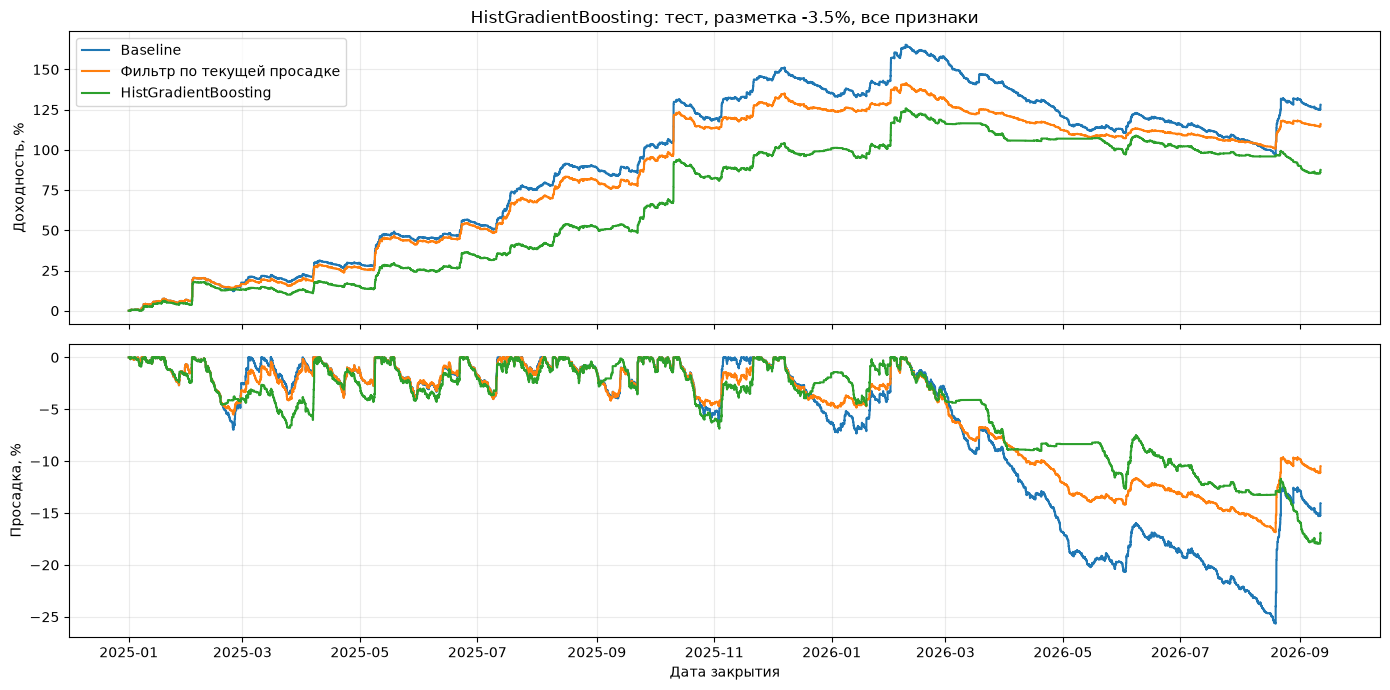

In [14]:
study_hist_boosting = run_study(
    labels_1, -3.5, classifier=HistGradientBoostingClassifier(random_state=42),
    method_name='HistGradientBoosting'
)

### Моделирование: AdaBoost (−3,5%)

ML: порог сигнала 0.50, объём ×0.5; обычный фильтр: порог -3.5%, объём ×0.5.


Threshold  Reduced_multiplier  Selected  \
Method                     Config_ID                                            
Baseline                   0                NaN                1.00     False   
AdaBoost                   13              0.50                0.50      True   
                           12              0.50                0.00     False   
                           15              0.55                0.00     False   
                           14              0.50                0.75     False   
                           16              0.55                0.50     False   
                           10              0.45                0.50     False   
                           18              0.60                0.00     False   
                           17              0.55                0.75     False   
                           19              0.60                0.50     False   
                           11              0.45                0.75     False   
                           20              0.60                0.75     False   
                           2               0.30                0.75     False   
                           24              0.70                0.00     False   
                           25              0.70                0.50     False   
                           26              0.70                0.75     False   
                           23              0.65                0.75     False   
                           22              0.65                0.50     False   
                           8               0.40                0.75     False   
                           21              0.65                0.00     False   
                           7               0.40                0.50     False   
                           1               0.30                0.50     False   
                           5               0.35                0.75     False   
                           9               0.45                0.00     False   
                           4               0.35                0.50     False   
                           6               0.40                0.00     False   
                           3               0.35                0.00     False   
                           0               0.30                0.00     False   
Фильтр по текущей просадке 13             -3.50                0.50      True   
                           22             -2.00                0.50     False   
                           10             -4.00                0.50     False   
                           16             -3.00                0.50     False   
                           1              -5.50                0.50     False   
                           0              -5.50                0.00     False   
                           7              -4.50                0.50     False   
                           19             -2.50                0.50     False   
                           12             -3.50                0.00     False   
                           4              -5.00                0.50     False   
                           14             -3.50                0.75     False   
                           6              -4.50                0.00     False   
                           11             -4.00                0.75     False   
                           2              -5.50                0.75     False   
                           23             -2.00                0.75     False   
                           17             -3.00                0.75     False   
                           8              -4.50                0.75     False   
                           25             -1.50                0.50     False   
                           5              -5.00                0.75     False   
                           20             -2.50                0.75  

,Дней,Дней класса 1,Эпизодов класса 1,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision,Brier,TN,FP,FN,TP
Валидация,723.0,203.0,8.0,0.831,0.742,0.796,0.537,0.641,0.819,0.707,0.177,492.0,28.0,94.0,109.0
Тест,588.0,341.0,9.0,0.736,0.762,0.915,0.601,0.726,0.853,0.890,0.203,228.0,19.0,136.0,205.0


,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Фильтр по текущей просадке,243822.281,90.665,-25105.692,116.176,57.601,16.848,13.913,15.082,3.419,2.856,2.518,9.581,215.0,87.561,8.0,283.0,0.781,43.786,0.0,19.0,10.336,15.272,12.704,15.913
AdaBoost,214597.641,79.797,-54330.332,102.251,51.529,20.390,16.957,18.479,2.527,2.103,2.215,8.138,215.0,88.207,8.0,296.0,0.809,38.243,0.0,85.0,13.112,18.804,14.394,19.453


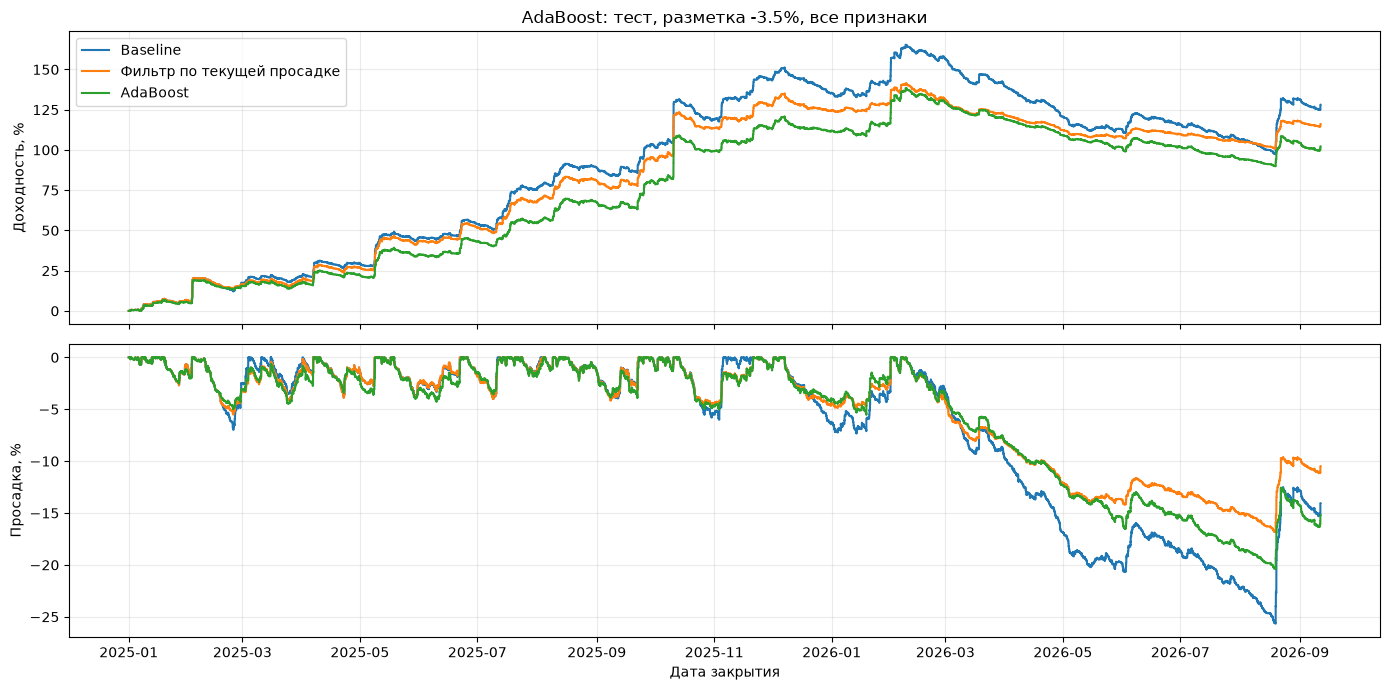

In [15]:
study_adaboost = run_study(
    labels_1, -3.5, classifier=AdaBoostClassifier(random_state=42),
    method_name='AdaBoost'
)

In [16]:
comparison = pd.DataFrame({
    depth: {'Порог сигнала': run['threshold'], 'Множитель': run['multiplier'],
            'Calmar валидации': run['validation_calmar'],
            **run['summary'].loc[run['method_name'], ['Net_PnL_USDT', 'MDD_pct', 'Calmar']]}
    for depth, run in [('−3,5%: все признаки', study_1), ('−2%: все признаки', study_2),
                       ('−5%: все признаки', study_3), ('−3,5%: только глубина', study_depth_only),
                       ('−3,5%: градиентный бустинг', study_boosting), ('−3,5%: CatBoost', study_catboost),
                       ('−3,5%: HistGradientBoosting', study_hist_boosting), ('−3,5%: AdaBoost', study_adaboost)]
}).T.rename_axis('Модель')
display(comparison.round(3))

,Порог сигнала,Множитель,Calmar валидации,Net_PnL_USDT,MDD_pct,Calmar
Модель,,,,,,
"−3,5%: все признаки",0.60,0.0,22.084,206146.053,6.270,7.933
−2%: все признаки,0.40,0.5,20.477,240379.019,14.563,3.907
−5%: все признаки,0.30,0.5,19.757,244712.319,17.195,3.360
"−3,5%: только глубина",0.55,0.5,21.835,242355.592,16.897,3.391
"−3,5%: градиентный бустинг",0.35,0.5,21.761,211213.951,20.922,2.429
"−3,5%: CatBoost",0.70,0.0,22.322,164001.294,21.773,1.864
"−3,5%: HistGradientBoosting",0.50,0.0,24.460,183937.120,17.957,2.504
"−3,5%: AdaBoost",0.50,0.5,22.402,214597.641,20.390,2.527


# 4. SHAP

Разметка −3,5%, сигнал ≥ 0,60 → ×0, возврат при сигнале < 0,60. Используем готовую модель способа 1. Модель, признаки и торговое правило не меняем.

Вклады перекрывающихся окон суммируем по семействам: доходность, win rate и число закрытий. Глубина и длительность просадки показаны отдельно. Объясняем все даты теста 2025–2026, а в качестве опоры оставляем обучение 2021–2022. Слева — средний модуль группового вклада на тесте, справа — вклады на начало последней паузы. В Beeswarm каждая точка — один день; цвет обозначает знак вклада, поскольку у группы из нескольких окон нет одного исходного значения. Вклады измерены в логарифме шансов класса `1`, не в процентах.

Для линейной модели используем [точную формулу interventional SHAP](https://shap.readthedocs.io/en/stable/generated/shap.LinearExplainer.html) с опорой на обучающие данные. Это объяснение оценки модели, а не причин просадки или эффекта на PnL.

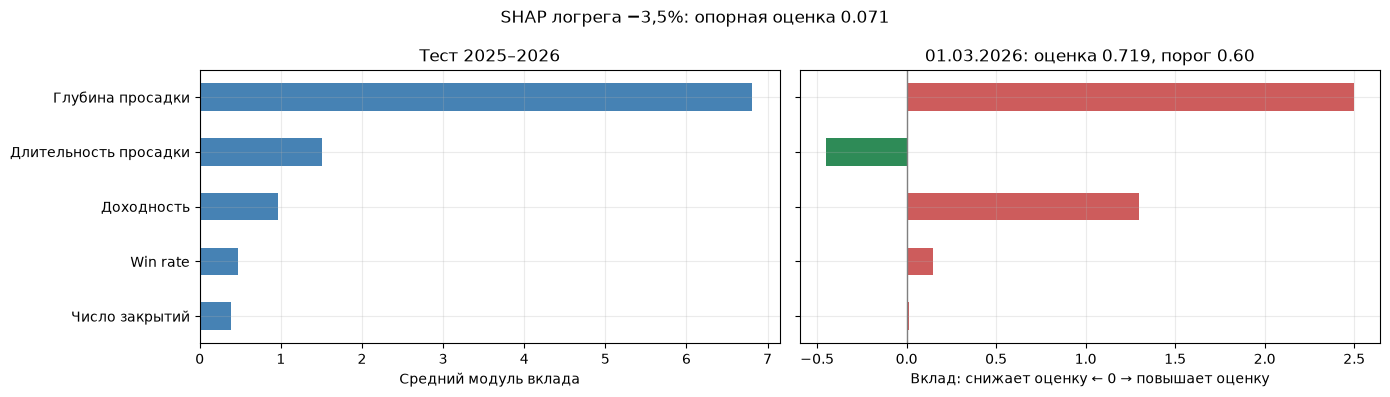

In [17]:
shap_model = study_1['model']
shap_threshold = study_1['threshold']
x_train_shap = features.loc[study_1['labels'][0].index]
x_test_shap = features.loc[test_days]
shap_transform = shap_model[:-1]
shap_logreg = shap_model[-1]

shap_reference = shap_transform.transform(x_train_shap).mean(axis=0)
shap_values = pd.DataFrame(
    (shap_transform.transform(x_test_shap) - shap_reference) * shap_logreg.coef_[0],
    index=x_test_shap.index, columns=x_test_shap.columns
)
shap_base = float(shap_logreg.intercept_[0] + shap_reference @ shap_logreg.coef_[0])
shap_groups = {
    'Глубина просадки': ['drawdown_pct'],
    'Длительность просадки': ['days_underwater'],
    'Доходность': [f'return_{days}d' for days in windows],
    'Win rate': [f'winrate_{days}d' for days in windows],
    'Число закрытий': [f'closes_{days}d' for days in windows],
}
shap_grouped = pd.DataFrame({
    name: shap_values[columns].sum(axis=1) for name, columns in shap_groups.items()
})
shap_importance = shap_grouped.abs().mean().sort_values()

shap_score = study_1['probability'].loc[shap_grouped.index]
shap_restricted = shap_score.ge(shap_threshold)
shap_starts = shap_restricted & ~shap_restricted.shift(fill_value=False)
shap_start_dates = shap_starts.index[shap_starts]
shap_example = shap_start_dates[-1] if len(shap_start_dates) else shap_score.idxmax()
shap_local = shap_grouped.loc[shap_example, shap_importance.index]
shap_reference_score = 1 / (1 + np.exp(-shap_base))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
shap_importance.plot.barh(ax=axes[0], color='steelblue')
shap_local.plot.barh(ax=axes[1], color=np.where(shap_local.ge(0), 'indianred', 'seagreen'))
axes[0].set(title='Тест 2025–2026', xlabel='Средний модуль вклада')
axes[1].axvline(0, color='gray', linewidth=1)
axes[1].set(
    title=f'{shap_example:%d.%m.%Y}: оценка {shap_score.loc[shap_example]:.3f}, порог {shap_threshold:.2f}',
    xlabel='Вклад: снижает оценку ← 0 → повышает оценку'
)
fig.suptitle(f'SHAP логрега −3,5%: опорная оценка {shap_reference_score:.3f}')
plt.tight_layout()
plt.show()